# 05 · Classification Algorithms and Their Variants - MEPS HC-243 (2022)

**Goal:** train every classification algorithm in the project plan, try the important **variants** of each, and understand *how* each one makes decisions.

| # | Algorithm | Variants tried | Library |
|---|---|---|---|
| 1 | Logistic Regression | L2, L1, ElasticNet; with/without class weights | scikit-learn |
| 2 | K-Nearest Neighbors | k, uniform/distance weighting, Euclidean/Manhattan, SMOTE | scikit-learn, imbalanced-learn |
| 3 | Decision Tree | Gini/Entropy, depth limits, minimum leaf size | scikit-learn |
| 4 | Random Forest | Fully grown vs regularised trees, `max_features`, Extra Trees | scikit-learn |
| 5 | Support Vector Machine | Linear, Polynomial, RBF, Sigmoid kernels | scikit-learn |
| 6 | Naive Bayes | Gaussian (learned / equal priors), Bernoulli | scikit-learn |
| 7 | Gradient Boosting | Classic `GradientBoosting` vs `HistGradientBoosting` | scikit-learn |
| 8 | XGBoost | Class weighting, depth, regularisation | xgboost |
| 9 | Voting ensemble | Hard vs soft voting | scikit-learn |

**Rules (same as notebook 04):**
- Training data only, the same 5 household-grouped folds, and the same preprocessing pipeline inside every model.
- The best variant of each algorithm is chosen with a **"one standard error" rule**:
  1. Every variant whose cross-validated ROC-AUC is within one fold-standard-deviation of the top score counts as **tied**, because the difference is just noise.
  2. Among the tied variants, the one with the higher **F1** (rounded to 2 decimals) wins, since it actually finds high-cost people at the default threshold.
  3. If still tied, the **fastest** wins.
- Notebook 06 then compares the winners head to head.

Hyperparameters here are sensible defaults, not tuned; tuning comes in notebook 07.

## Step 0 - Setup

**🛠️ What this code does:** Imports the libraries:
- **scikit-learn** for the models, `validation_curve`, `DecisionBoundaryDisplay` and `plot_tree`.
- **xgboost** for XGBoost.
- **imbalanced-learn**, via the project pipeline, for SMOTE.
- **pandas, NumPy, Matplotlib, Seaborn** for tables and charts.

All model variants are defined in one place, `src/classification.py` (the `VARIANTS` dictionary), so notebook 06 can rebuild the winners by name.

In [1]:
import sys, json, time, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, validation_curve
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

from src.preprocessing import (load_split, load_selected_features, build_preprocessor, cv_folds,
                               LABEL_COL, GROUP_COL, RANDOM_STATE)
from src.feature_engineering import feature_groups
from src.classification import VARIANTS, ALGORITHMS, build, make_pipeline, save_best_variants
from src.evaluation import evaluate_cv, summarize, pick_best_variant, METRIC_LABELS
from src.visualization import (SERIES, LOW_COST_COLOR, HIGH_COST_COLOR, INK, INK_SECONDARY, INK_MUTED,
                               SURFACE, DIVERGING, apply_style, save_fig, model_color, plot_variant_scores)

apply_style()
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 60)
RESULTS = ROOT / "reports" / "results"
print("Libraries loaded.")

Libraries loaded.


## Step 1 - Data, folds and a helper to score variants

**🛠️ What this code does:** Loads the training data, recreates the same 5 folds and the preprocessing pipeline, and defines `run_variants()`. That helper trains every variant of one algorithm on the 5 folds, prints how long each took, and shows one row per variant:
- **ROC-AUC and PR-AUC:** threshold-free ranking skill (± is the fold-to-fold standard deviation).
- **F1, recall and precision:** behaviour at the default threshold.
- **Train ROC-AUC:** the score on the data the model trained on. A big gap above the validation ROC-AUC means **overfitting**.
- **Fit time:** seconds to train once.

It also applies the selection rule (`pick_best_variant` in `src/evaluation.py`) and prints the chosen variant.

In [2]:
train, _ = load_split()
features = load_selected_features()
X, y, groups = train[features], train[LABEL_COL], train[GROUP_COL]
folds = cv_folds(X, y, groups)
preprocessor = build_preprocessor(features)
pos_weight = float((y == 0).sum() / (y == 1).sum())

ALL = {}          # algorithm -> table of variant scores
BEST = {}         # algorithm -> chosen variant
COLS = {"roc_auc": "ROC-AUC", "roc_auc_std": "±", "pr_auc": "PR-AUC", "f1": "F1", "recall": "Recall",
        "precision": "Precision", "train_roc_auc": "Train ROC-AUC", "fit_time_s": "Fit time (s)"}

def run_variants(algorithm, X_=X, y_=y, folds_=folds, n_jobs=None):
    """Score every variant of one algorithm on the fixed folds and show the table."""
    res = {}
    for variant in VARIANTS[algorithm]:
        model, sampler = build(algorithm, variant, pos_weight)
        t0 = time.perf_counter()
        res[variant] = evaluate_cv(make_pipeline(preprocessor, model, sampler), X_, y_, folds_, n_jobs=n_jobs)
        print(f"  {variant:<42} {time.perf_counter() - t0:6.1f} s")
    table = summarize(res).astype(float).reindex(columns=list(COLS))
    ALL[algorithm] = table
    BEST[algorithm] = pick_best_variant(table)
    display(table.round(3).rename(columns=COLS))
    print(f"Chosen variant (one-standard-error rule): {BEST[algorithm]}")
    return table, res

print(f"{len(X):,} training people, {len(features)} features, {len(folds)} folds, class ratio {pos_weight:.2f}")

17,398 training people, 37 features, 5 folds, class ratio 4.00


**📖 What the result shows:**
Everything is ready. Each algorithm below follows the same pattern: **🎓 how it works → 🛠️ train its variants → 📖 what the result shows**.

## 1 · Logistic Regression

> **🎓 Theory in brief**
>
> Logistic regression adds up the features, each multiplied by a learned **weight** (coefficient), to get a score *z*. It then turns *z* into a probability with the sigmoid curve, p = 1 / (1 + e^(-z)). The decision boundary (p = 0.5) is a straight line, or a flat plane in many dimensions.
> 
> **Regularisation** stops weights from growing too large, which reduces overfitting:
> - **L2 (Ridge)** shrinks all weights a little.
> - **L1 (Lasso)** can push weights to exactly 0, which selects features.
> - **ElasticNet** mixes the two (`l1_ratio = 0.5`).
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#101-logistic-regression)*

**🛠️ What this code does:** Trains the four logistic-regression variants (L2 without class weights, L2 / L1 / ElasticNet with balanced class weights) and charts ROC-AUC, PR-AUC and F1. The chosen variant is drawn in solid colour.

  L2, no class weight                           3.7 s


  L2 + balanced                                 1.3 s


  L1 + balanced                                 6.7 s


  ElasticNet + balanced                        54.3 s


,ROC-AUC,±,PR-AUC,F1,Recall,Precision,Train ROC-AUC,Fit time (s)
"L2, no class weight",0.822,0.003,0.567,0.446,0.340,0.649,0.828,0.563
L2 + balanced,0.822,0.004,0.566,0.543,0.724,0.434,0.828,0.601
L1 + balanced,0.822,0.003,0.565,0.543,0.724,0.435,0.828,4.634
ElasticNet + balanced,0.822,0.004,0.565,0.543,0.724,0.434,0.828,46.327


Chosen variant (one-standard-error rule): L2 + balanced


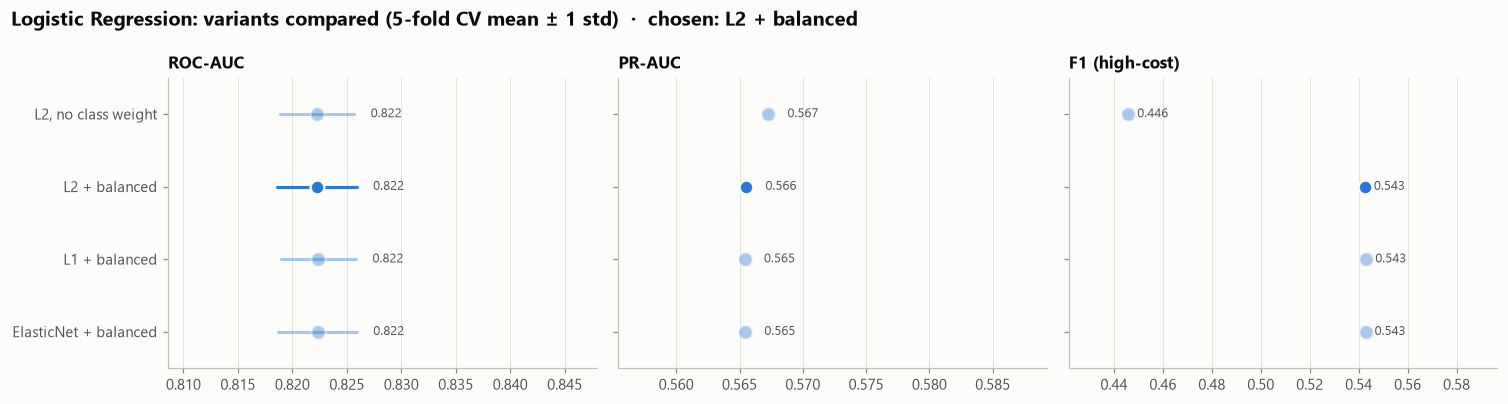

In [3]:
table, res = run_variants("Logistic Regression", n_jobs=5)
fig = plot_variant_scores(table, "Logistic Regression", best=BEST["Logistic Regression"])
save_fig(fig, "05_variants_logistic_regression")
plt.show()

#### 📖 What this chart shows (in plain English)
- All four variants have essentially the **same ranking skill**: ROC-AUC 0.822 and PR-AUC ≈ 0.566. The type of regularisation makes no real difference here. With 17,000 people and only 110 columns there is little overfitting to prevent (training ROC-AUC is 0.828).
- The only big difference is at the **0.5 threshold**: without class weights recall is just **0.34**, while with balanced weights it is **0.72** (F1 0.446 → 0.543).
- L1 and ElasticNet are **slower** (6 s and 56 s per fit, against 0.6 s for L2) and give nothing extra.

**Chosen: L2 + balanced.** It ties on ROC-AUC and F1, and it is the fastest.

**🛠️ What this code does:** Fits the balanced L2 model once on all the training data and plots its **15 largest positive and negative coefficients**. Inputs are standardised, so a coefficient shows how much the log-odds of being high-cost change when that input goes up by one standard deviation, or when a one-hot category switches on.

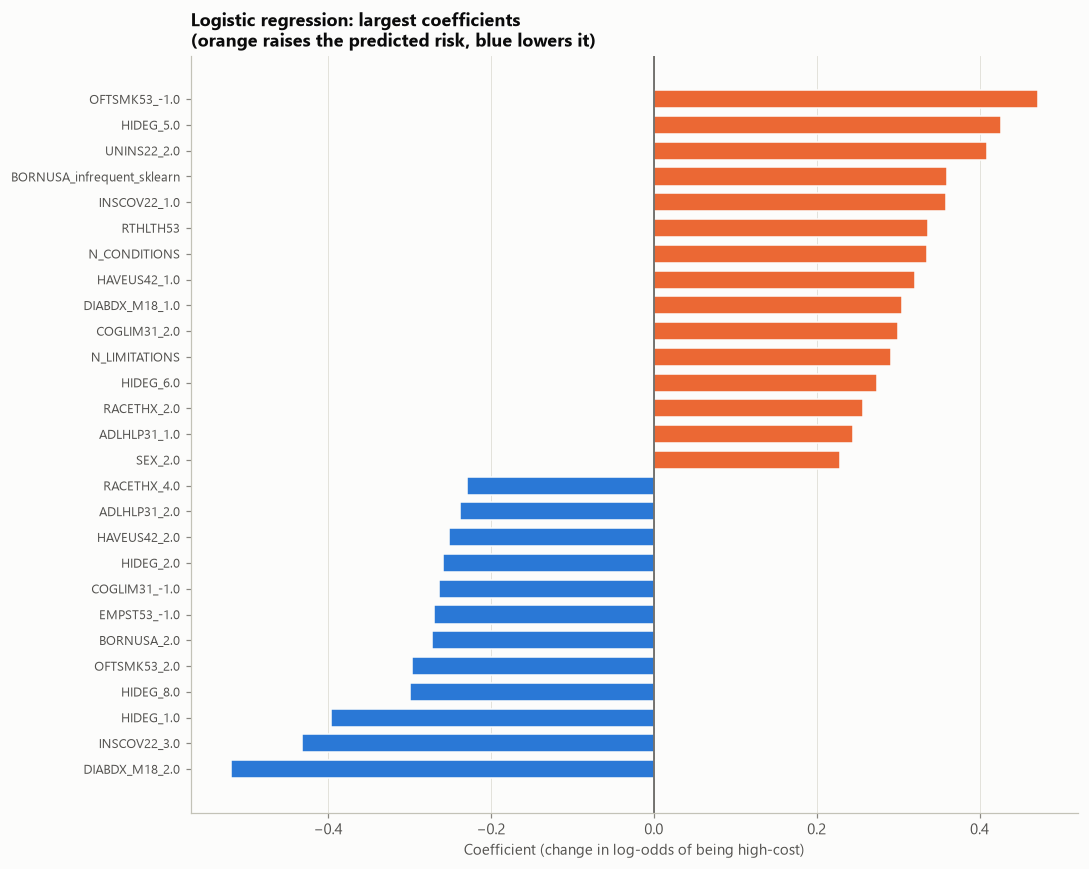

In [4]:
lr_pipe = make_pipeline(preprocessor, *build("Logistic Regression", "L2 + balanced", pos_weight)).fit(X, y)
names = [n.split("__", 1)[1] for n in lr_pipe.named_steps["prep"].get_feature_names_out()]
coef = pd.Series(lr_pipe.named_steps["model"].coef_[0], index=names).sort_values()
show = pd.concat([coef.head(12), coef.tail(15)])

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(show.index, show.values, color=[HIGH_COST_COLOR if v > 0 else LOW_COST_COLOR for v in show.values],
        height=0.7, edgecolor=SURFACE, linewidth=1)
ax.axvline(0, color=INK_SECONDARY, linewidth=1)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8.5)
ax.set_xlabel("Coefficient (change in log-odds of being high-cost)")
ax.set_title("Logistic regression: largest coefficients\n(orange raises the predicted risk, blue lowers it)")
fig.tight_layout()
save_fig(fig, "05_logistic_coefficients")
plt.show()

#### 📖 What this chart shows (in plain English)
Orange bars push the prediction towards **high-cost**, blue bars towards **low-cost**. Each one-hot coefficient is measured *relative to the other categories of the same feature*.

- **Diabetes:** `DIABDX_M18_2.0` ("no diabetes") has the strongest negative weight, so having diabetes raises the predicted risk.
- **Insurance:** `INSCOV22_3.0` (uninsured) strongly *lowers* predicted cost, while `INSCOV22_1.0` (any private) and `UNINS22_2.0` (not uninsured all year) raise it. Insured people use more care.
- **Health burden:** `N_CONDITIONS`, `RTHLTH53` (a higher number means worse self-rated health), `N_LIMITATIONS` and needing help with daily activities (`ADLHLP31_1.0`) all raise the risk.
- **Usual source of care** (`HAVEUS42_1.0`): people with a regular doctor have more recorded care.
- Some large weights, such as `OFTSMK53_-1` (smoking question not asked, +) and `HIDEG_8.0` (under 16, −), largely **cancel each other out**. Both mostly describe children, so the model splits the "child" effect between correlated columns. This is why individual coefficients of correlated features shouldn't be over-interpreted.

These are **associations the model uses, not causes**.

## 2 · K-Nearest Neighbors (KNN)

> **🎓 Theory in brief**
>
> KNN doesn't learn weights at all. To classify a person, it finds the **k most similar people** in the training data and lets them vote. The share of high-cost neighbours is the predicted probability.
> - **k** controls smoothness. A small k follows noise (overfitting); a large k blurs everything (underfitting).
> - **Weighting:** "uniform" gives every neighbour one vote; "distance" gives closer neighbours more say.
> - **Distance metric:** Euclidean is the straight-line distance; Manhattan is the "city-block" distance, adding up the differences.
> - Because everything depends on distance, **feature scaling is essential**.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#102-k-nearest-neighbors)*

**🛠️ What this code does:** Trains five KNN variants: k = 15 vs 75, uniform vs distance weighting, Euclidean vs Manhattan, and k = 75 with SMOTE. KNN has no `class_weight` option, so SMOTE is its way of handling imbalance.

  k=15, uniform, euclidean                     14.4 s


  k=75, uniform, euclidean                     16.4 s


  k=75, distance-weighted                      16.1 s


  k=75, manhattan                             108.5 s


  k=75 + SMOTE                                 23.5 s


,ROC-AUC,±,PR-AUC,F1,Recall,Precision,Train ROC-AUC,Fit time (s)
"k=15, uniform, euclidean",0.785,0.008,0.487,0.387,0.280,0.627,0.859,0.171
"k=75, uniform, euclidean",0.811,0.004,0.539,0.359,0.243,0.695,0.828,0.223
"k=75, distance-weighted",0.811,0.004,0.545,0.360,0.244,0.693,1.000,0.229
"k=75, manhattan",0.809,0.006,0.536,0.328,0.214,0.704,0.828,0.238
k=75 + SMOTE,0.806,0.004,0.516,0.493,0.822,0.352,0.834,0.385


Chosen variant (one-standard-error rule): k=75, uniform, euclidean


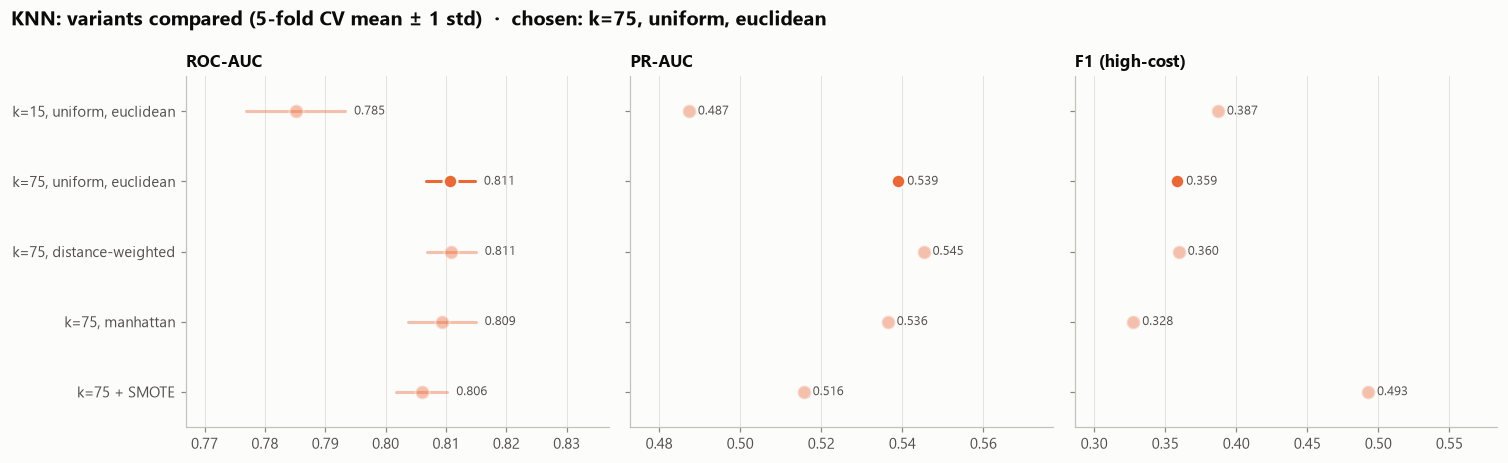

In [5]:
table, res = run_variants("KNN", n_jobs=5)
fig = plot_variant_scores(table, "KNN", best=BEST["KNN"])
save_fig(fig, "05_variants_knn")
plt.show()

#### 📖 What this chart shows (in plain English)
- **k = 15 overfits:** training ROC-AUC 0.859, validation 0.785. **k = 75** does better at 0.811.
- **Distance weighting** gives the same validation score, but a perfect training score (1.000), because each training person is their own nearest neighbour. That is pure memorisation.
- **Manhattan ≈ Euclidean** (0.809 vs 0.811), but it was much slower here (113 s in total).
- KNN has **no class weights**, so recall at 0.5 is low (≈ 0.24). With a 20% base rate, a majority of 75 neighbours is rarely high-cost. **SMOTE** raises recall to 0.82 but lowers ROC-AUC (0.806), because the synthetic people distort the neighbourhoods.
- Overall, KNN is below logistic regression (0.811 vs 0.822).

**Chosen: k = 75, uniform, Euclidean.** It ties with distance weighting on ROC-AUC and F1, and it is faster.

**🛠️ What this code does:** Draws a **validation curve**: training and validation ROC-AUC for k from 5 to 600. This is the clearest picture of the bias-variance trade-off.

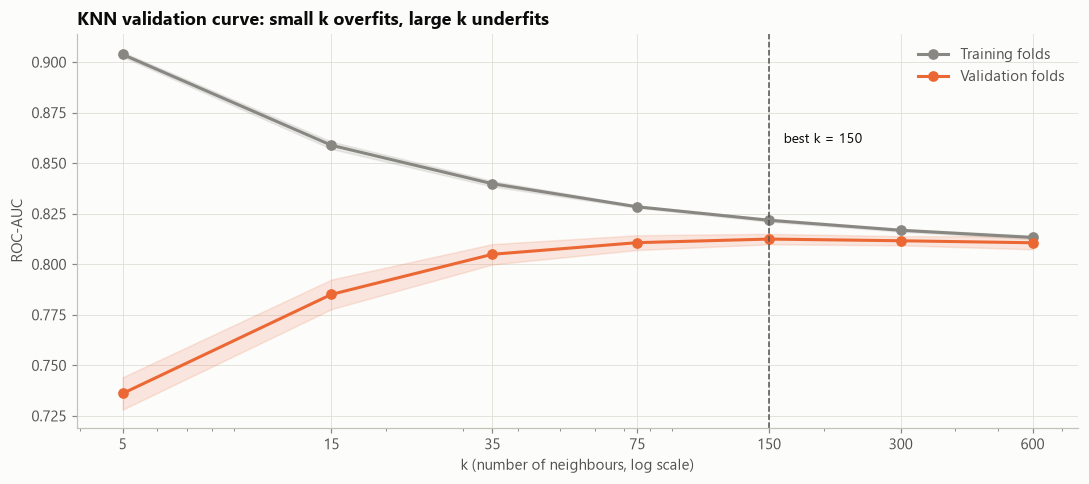

  k  train ROC-AUC  validation ROC-AUC
  5          0.904               0.736
 15          0.859               0.785
 35          0.840               0.805
 75          0.828               0.811
150          0.822               0.812
300          0.817               0.812
600          0.813               0.811


In [6]:
k_range = [5, 15, 35, 75, 150, 300, 600]
knn_pipe = make_pipeline(preprocessor, KNeighborsClassifier())
tr_s, va_s = validation_curve(knn_pipe, X, y, param_name="model__n_neighbors", param_range=k_range,
                              cv=folds, scoring="roc_auc", n_jobs=5)

fig, ax = plt.subplots(figsize=(10, 4.5))
for scores, name, color in [(tr_s, "Training folds", INK_MUTED), (va_s, "Validation folds", model_color("KNN"))]:
    ax.plot(k_range, scores.mean(1), marker="o", color=color, label=name)
    ax.fill_between(k_range, scores.mean(1) - scores.std(1), scores.mean(1) + scores.std(1), color=color, alpha=0.15)
best_k = k_range[int(np.argmax(va_s.mean(1)))]
ax.axvline(best_k, color=INK_SECONDARY, linestyle="--", linewidth=1)
ax.text(best_k * 1.08, 0.86, f"best k = {best_k}", fontsize=9)
ax.set_xscale("log"); ax.set_xticks(k_range, [str(k) for k in k_range])
ax.set_xlabel("k (number of neighbours, log scale)")
ax.set_ylabel("ROC-AUC")
ax.legend()
ax.set_title("KNN validation curve: small k overfits, large k underfits")
fig.tight_layout()
save_fig(fig, "05_knn_validation_curve")
plt.show()
print(pd.DataFrame({"k": k_range, "train ROC-AUC": tr_s.mean(1), "validation ROC-AUC": va_s.mean(1)}).round(3).to_string(index=False))

#### 📖 What this chart shows (in plain English)
Grey is the score on the training folds; orange is the score on the validation folds.

- **k = 5:** training 0.904 vs validation 0.736. This is **overfitting**: each prediction depends on just 5 people, so noise dominates.
- As k grows, the training score falls and the validation score rises. They meet around **k = 150-300** (validation ≈ 0.812).
- At **k = 600** both start to dip. Too many neighbours blur the pattern, which is the start of **underfitting**.
- The plateau from 75 to 600 is very flat, so the k = 75 used in the variants is close to the best.

**🛠️ What this code does:** **Shows why scaling matters for KNN.** It builds a second preprocessing pipeline that imputes and one-hot encodes but does **not** scale, then compares KNN (k = 75) with and without scaling.

In [7]:
g = feature_groups(features)
unscaled_prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), g["numeric"] + g["skewed"] + g["ordinal"]),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", drop="if_binary",
                                               min_frequency=50, sparse_output=False))]), g["categorical"]),
], verbose_feature_names_out=True)

scaling = {}
for name, prep in [("With scaling", preprocessor), ("Without scaling", unscaled_prep)]:
    r = evaluate_cv(make_pipeline(prep, KNeighborsClassifier(n_neighbors=75)), X, y, folds, n_jobs=5, train_score=False)
    scaling[name] = r
display(summarize(scaling)[["roc_auc", "pr_auc"]].astype(float).round(3).rename(columns=METRIC_LABELS))
print(f"Raw ranges: POVLEV22 {X.POVLEV22.min():,.0f} to {X.POVLEV22.max():,.0f}  |  "
      f"AGELAST {X.AGELAST.min()} to {X.AGELAST.max()}  |  N_CONDITIONS {X.N_CONDITIONS.min()} to {X.N_CONDITIONS.max()}")

,ROC-AUC,PR-AUC
With scaling,0.811,0.539
Without scaling,0.727,0.388


Raw ranges: POVLEV22 -2,190 to 4,239  |  AGELAST 0 to 85  |  N_CONDITIONS 0 to 12


**📖 What the result shows:**
Without scaling, ROC-AUC drops from **0.811 to 0.727** and PR-AUC from **0.539 to 0.388**.

The reason is the raw ranges: `POVLEV22` spans about 6,400 units, age 85 and the number of conditions only 12. Without scaling, the "nearest" neighbours are simply people with similar income, and health, the strongest signal, barely counts in the distance. Scaling puts every feature on an equal footing.

## 3 · Decision Tree

> **🎓 Theory in brief**
>
> A decision tree asks a series of yes/no questions ("Is age > 62?", "Has 3+ conditions?") and ends at a **leaf** that gives a prediction.
> - At each **node** it picks the question that makes the two resulting groups as "pure" as possible, meaning each group is mostly one class.
> - Purity is measured by **Gini impurity** (1 − Σp²) or **entropy** (−Σp·log₂p). The improvement from a split is the **information gain**.
> - Left alone, a tree keeps splitting until every leaf is pure, which memorises the training data. **Depth limits** and **minimum leaf sizes** prevent this.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#103-decision-tree)*

**🛠️ What this code does:** Trains four tree variants: no depth limit, depth 6 with Gini, depth 6 with entropy, and a minimum of 100 people per leaf.

  Gini, no depth limit                          1.6 s


  Gini, max_depth=6                             1.3 s


  Entropy, max_depth=6                          1.2 s


  Gini, min_samples_leaf=100                    1.4 s


,ROC-AUC,±,PR-AUC,F1,Recall,Precision,Train ROC-AUC,Fit time (s)
"Gini, no depth limit",0.611,0.011,0.267,0.377,0.378,0.377,1.000,0.698
"Gini, max_depth=6",0.791,0.006,0.489,0.513,0.710,0.403,0.821,0.315
"Entropy, max_depth=6",0.792,0.005,0.487,0.509,0.726,0.395,0.820,0.328
"Gini, min_samples_leaf=100",0.795,0.004,0.504,0.512,0.739,0.392,0.829,0.421


Chosen variant (one-standard-error rule): Entropy, max_depth=6


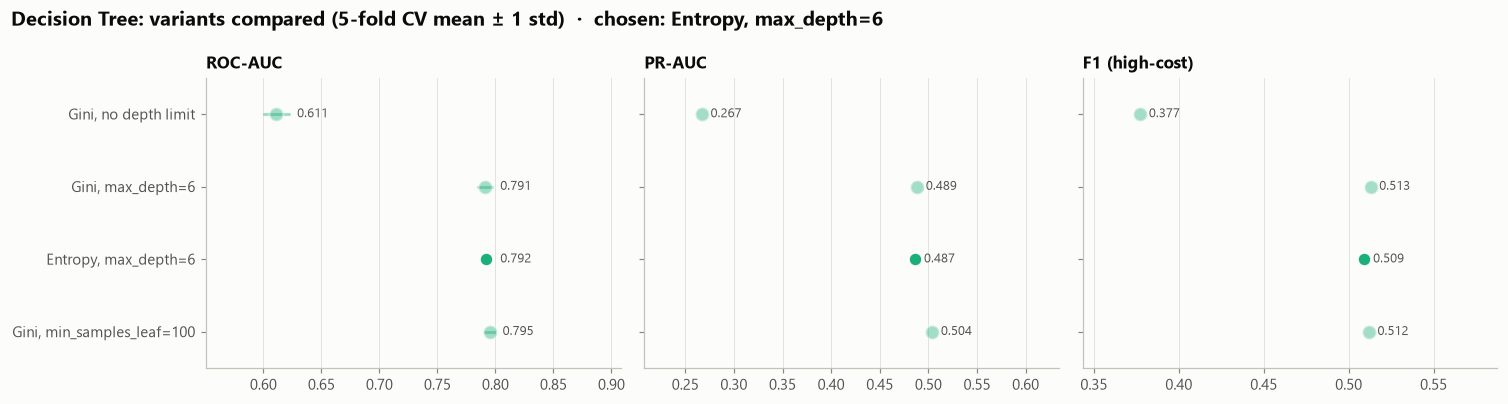

In [8]:
table, res = run_variants("Decision Tree", n_jobs=5)
fig = plot_variant_scores(table, "Decision Tree", best=BEST["Decision Tree"])
save_fig(fig, "05_variants_decision_tree")
plt.show()

#### 📖 What this chart shows (in plain English)
- **No depth limit:** training 1.000 vs validation 0.611. This is the textbook overfit: the tree memorises every training person.
- Limiting the depth to 6, or requiring at least 100 people per leaf, brings validation up to **≈ 0.79-0.795**.
- **Gini vs entropy:** no meaningful difference (0.791 vs 0.792).
- Even the best single tree (≈ 0.795) stays below logistic regression (0.822). One tree's step-shaped boundary is coarse and unstable. Forests and boosting fix this by combining many trees.

**Chosen: Entropy, max_depth=6.** It ties with `min_samples_leaf=100` on ROC-AUC (0.792 vs 0.795, within one standard deviation) and on F1, and it is the fastest.

**🛠️ What this code does:** Draws the validation curve for **tree depth** (1 to 20): how training and validation ROC-AUC change as the tree is allowed to grow deeper.

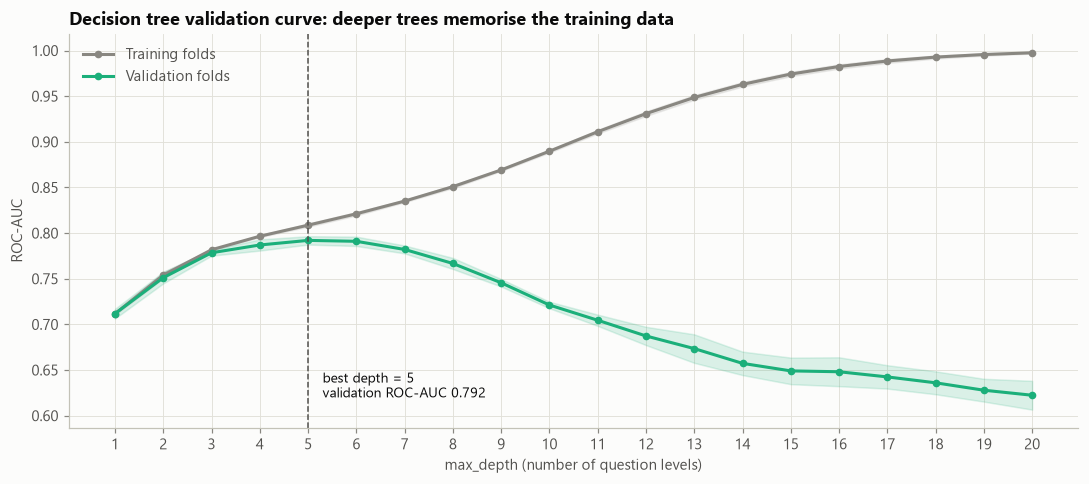

In [9]:
depths = list(range(1, 21))
dt_pipe = make_pipeline(preprocessor, DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))
tr_s, va_s = validation_curve(dt_pipe, X, y, param_name="model__max_depth", param_range=depths,
                              cv=folds, scoring="roc_auc", n_jobs=5)
fig, ax = plt.subplots(figsize=(10, 4.5))
for scores, name, color in [(tr_s, "Training folds", INK_MUTED), (va_s, "Validation folds", model_color("Decision Tree"))]:
    ax.plot(depths, scores.mean(1), marker="o", markersize=4, color=color, label=name)
    ax.fill_between(depths, scores.mean(1) - scores.std(1), scores.mean(1) + scores.std(1), color=color, alpha=0.15)
best_depth = depths[int(np.argmax(va_s.mean(1)))]
ax.axvline(best_depth, color=INK_SECONDARY, linestyle="--", linewidth=1)
ax.text(best_depth + 0.3, 0.62, f"best depth = {best_depth}\nvalidation ROC-AUC {va_s.mean(1).max():.3f}", fontsize=9)
ax.set_xticks(depths)
ax.set_xlabel("max_depth (number of question levels)")
ax.set_ylabel("ROC-AUC")
ax.legend(loc="upper left")
ax.set_title("Decision tree validation curve: deeper trees memorise the training data")
fig.tight_layout()
save_fig(fig, "05_tree_depth_curve")
plt.show()

#### 📖 What this chart shows (in plain English)
- **Depth 1-3:** both curves rise together. The tree is still learning real patterns (it was underfitting before).
- **Best validation score at depth 5** (0.792).
- **Beyond depth 6**, the training score climbs towards 1.0 while the validation score falls to 0.62 at depth 20. Each extra level memorises ever smaller groups of people.

This is the bias-variance trade-off in one picture.

**🛠️ What this code does:** Fits a small, readable tree (depth 3, at least 100 people per leaf, **no** class weights) on the *unscaled* data, so the questions use real units like "age ≤ 59.5", and draws it.
- **gini:** the impurity of the node.
- **samples:** the share of training people who reach the node.
- **value:** the share of [low-cost, high-cost] people in the node.
- **Colour:** blue nodes are mostly low-cost; orange nodes have many high-cost people.

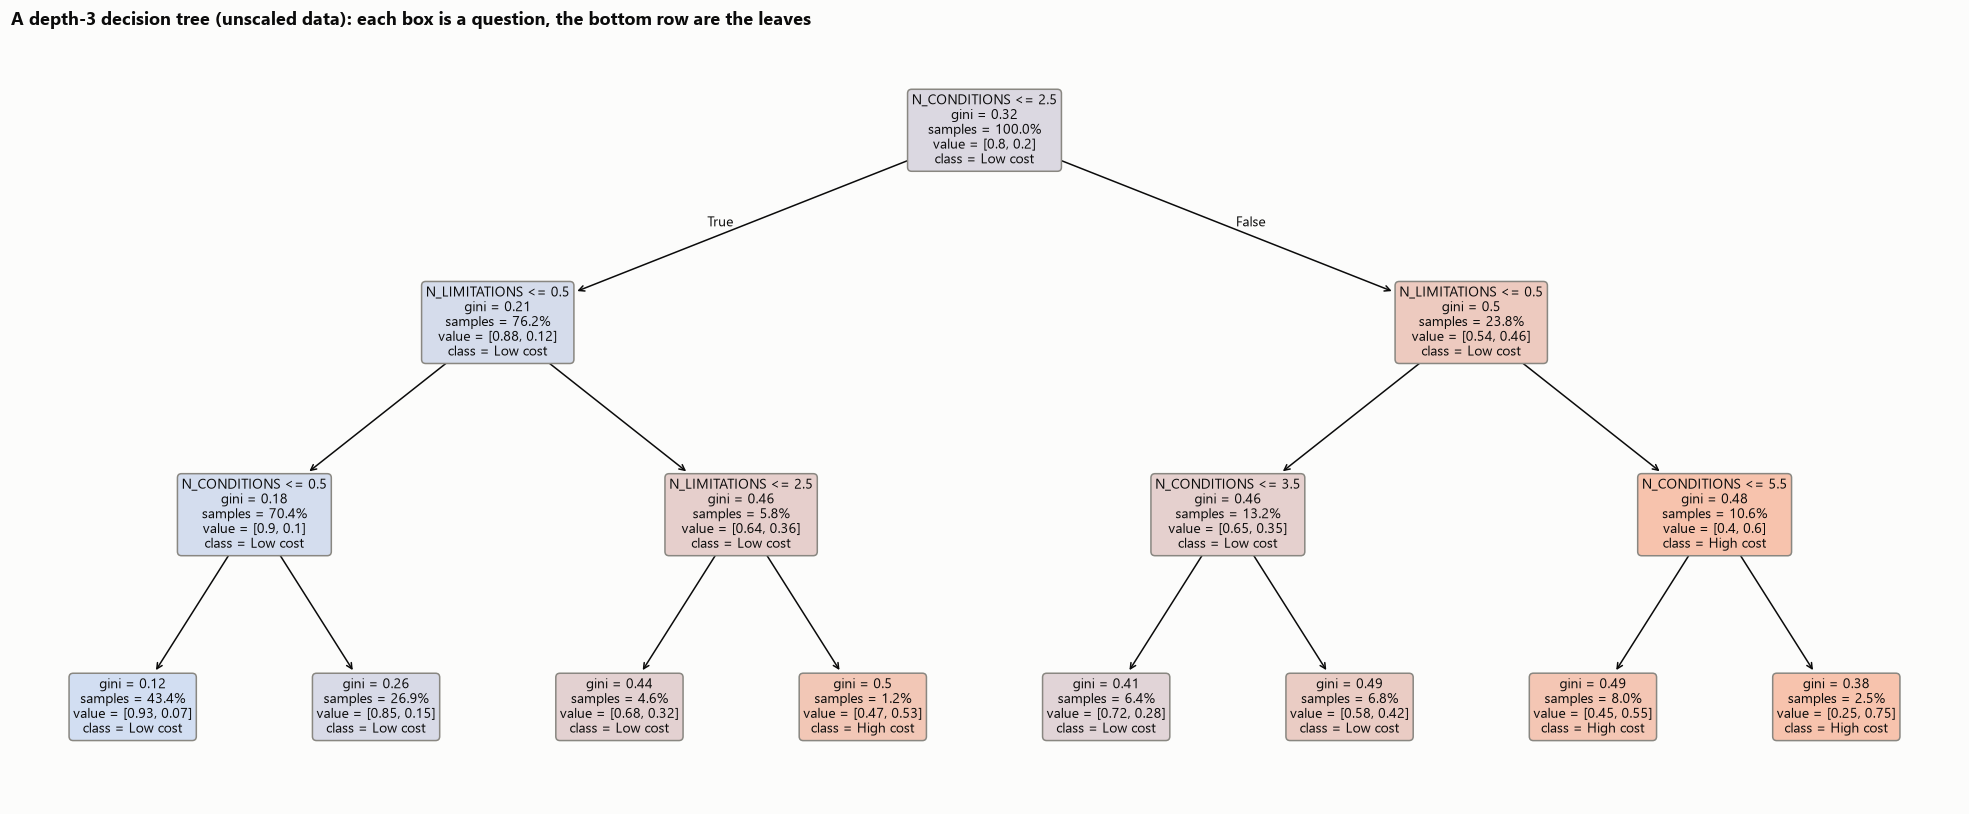

In [10]:
small_tree = Pipeline([("prep", clone(unscaled_prep)),
                       ("model", DecisionTreeClassifier(max_depth=3, min_samples_leaf=100, random_state=RANDOM_STATE))])
small_tree.fit(X, y)
tree = small_tree.named_steps["model"]
tree_names = [n.split("__", 1)[1] for n in small_tree.named_steps["prep"].get_feature_names_out()]

fig, ax = plt.subplots(figsize=(18, 7.5))
anns = plot_tree(tree, feature_names=tree_names, class_names=["Low cost", "High cost"], proportion=True,
                 impurity=True, rounded=True, precision=2, fontsize=9, ax=ax)
low, high = np.array(plt.matplotlib.colors.to_rgb("#cde2fb")), np.array(plt.matplotlib.colors.to_rgb("#f7c3ad"))
for ann in anns:                       # colour each node box by its share of high-cost people
    text, box = ann.get_text(), ann.get_bbox_patch()
    if "value = [" not in text or box is None:
        continue                       # skips the "True"/"False" arrow labels
    share_high = float(text.split("value = [")[1].split("]")[0].split(",")[1])
    t = min(share_high / 0.6, 1.0)     # 0% -> blue tint, 60%+ high-cost -> orange tint
    box.set_facecolor(low * (1 - t) + high * t)
    box.set_edgecolor(INK_MUTED)
ax.set_title("A depth-3 decision tree (unscaled data): each box is a question, the bottom row are the leaves")
fig.tight_layout()
save_fig(fig, "05_decision_tree_plot")
plt.show()

#### 📖 What this chart shows (in plain English)
Read it from the top:

- **Root:** "`N_CONDITIONS` ≤ 2.5?" is the single most useful first question. Everyone starts here (samples = 100%). 20% are high-cost (value = [0.8, 0.2]) and the gini impurity is 0.32.
- **Left branch (≤ 2 conditions, 76% of people):** only 12% are high-cost. **Right branch (3+ conditions, 24%):** 46% are high-cost.
- The **second level** splits both branches on the number of functional limitations.
- **Riskiest leaf** (far right): more than 5 conditions *and* at least one limitation, with **75% high-cost** (2.5% of people).
- **Safest leaf** (far left): no conditions and no limitations, with **7% high-cost** (43% of people). Its gini is 0.12, the purest node.
- A leaf is labelled "High cost" when more than half of its people are high-cost.

The tree uses only `N_CONDITIONS` and `N_LIMITATIONS`, the two engineered features, which confirms they are the strongest signals in the data.

## 4 · Random Forest

> **🎓 Theory in brief**
>
> A random forest grows **hundreds of different trees** and averages their votes.
> - **Bagging (bootstrap aggregating):** each tree trains on a *bootstrap sample*, a random sample of the rows drawn with replacement.
> - **Random feature selection:** at each split, a tree may only look at a random subset of features (`max_features`). This makes the trees different from each other.
> 
> Each single tree overfits in its own way, and averaging cancels much of that noise. **Extra Trees** adds even more randomness by choosing split points at random.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#104-random-forest)*

**🛠️ What this code does:** Trains four forest variants (300 trees each, balanced class weights per bootstrap sample): fully grown trees, trees with at least 5 people per leaf, the same with 30% of features per split, and Extra Trees.

  300 trees, fully grown                       16.7 s


  300 trees, min_samples_leaf=5                15.1 s


  300 trees, leaf=5, max_features=0.3          20.9 s


  Extra Trees, leaf=5                          14.0 s


,ROC-AUC,±,PR-AUC,F1,Recall,Precision,Train ROC-AUC,Fit time (s)
"300 trees, fully grown",0.811,0.002,0.531,0.388,0.282,0.621,1.000,2.228
"300 trees, min_samples_leaf=5",0.821,0.004,0.553,0.550,0.646,0.478,0.933,1.885
"300 trees, leaf=5, max_features=0.3",0.819,0.003,0.550,0.540,0.580,0.506,0.972,3.055
"Extra Trees, leaf=5",0.816,0.005,0.544,0.541,0.684,0.448,0.939,1.769


Chosen variant (one-standard-error rule): 300 trees, min_samples_leaf=5


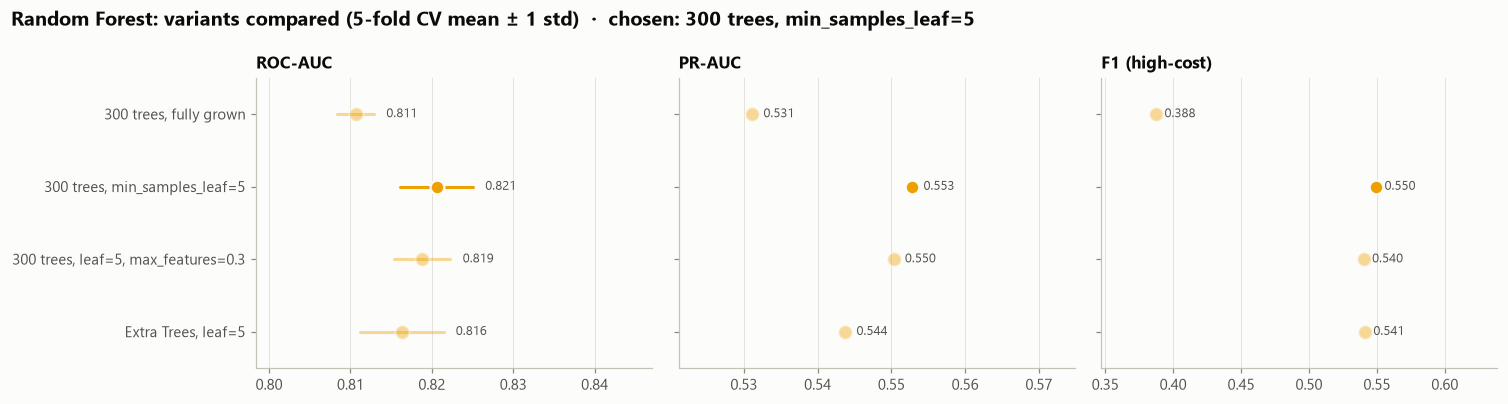

In [11]:
table, res = run_variants("Random Forest", n_jobs=None)   # forests already use all CPU cores
fig = plot_variant_scores(table, "Random Forest", best=BEST["Random Forest"])
save_fig(fig, "05_variants_random_forest")
plt.show()

#### 📖 What this chart shows (in plain English)
- **Fully grown trees:** training 1.000, validation 0.811. Averaging 300 overfitted trees still beats one overfitted tree by a lot (0.611 → 0.811), which shows bagging's variance reduction at work.
- **min_samples_leaf = 5:** validation **0.821**, the best. The training score (0.933) is still well above validation: the forest memorises somewhat, but averaging protects the validation score.
- `max_features = 0.3`: 0.819. Extra Trees: 0.816.
- The best forest only **matches** logistic regression (0.822). The extra flexibility of trees doesn't find extra signal.

**Chosen: 300 trees, min_samples_leaf = 5.**

## 5 · Support Vector Machine (SVM)

> **🎓 Theory in brief**
>
> An SVM looks for the boundary that separates the classes with the **widest possible margin**. The people closest to the boundary, the **support vectors**, define it.
> - **C** sets how many points may sit inside the margin or on the wrong side.
> - The **kernel trick** lets an SVM draw curved boundaries by implicitly mapping the data into a higher-dimensional space:
>   - **linear:** a straight boundary.
>   - **polynomial:** curved, built from feature products.
>   - **RBF:** flexible bumps around groups of points.
>   - **sigmoid:** behaves like a neural-network unit.
> 
> SVMs output a *decision value*, not a probability. That is fine for ROC-AUC and PR-AUC, which only need a ranking.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#105-support-vector-machine)*

**🛠️ What this code does:** Training time for kernel SVMs grows roughly with the *square* of the number of rows, so the four kernels are compared on a **5,000-person stratified subsample** with its own 5 household-grouped folds. For a fair reference, logistic regression is scored on the same subsample. Notebook 06 trains the winning kernel on all 17,398 people.

Subsample: 5,000 people, high-cost rate 20.0%


  Linear kernel                                 5.8 s


  Polynomial kernel (degree 3)                  5.8 s


  RBF kernel                                   11.5 s


  Sigmoid kernel                                3.8 s


,ROC-AUC,±,PR-AUC,F1,Recall,Precision,Train ROC-AUC,Fit time (s)
Linear kernel,0.833,0.012,0.583,0.556,0.727,0.450,0.849,2.812
Polynomial kernel (degree 3),0.804,0.012,0.500,0.537,0.693,0.438,0.916,1.882
RBF kernel,0.821,0.010,0.512,0.548,0.742,0.434,0.892,2.234
Sigmoid kernel,0.735,0.023,0.422,0.461,0.673,0.351,0.744,1.072


Chosen variant (one-standard-error rule): Linear kernel


Reference - logistic regression on the same 5,000 people:


,ROC-AUC,±,PR-AUC,F1,Recall,Precision,Train ROC-AUC,Fit time (s)
Logistic Regression (L2 + balanced),0.834,0.013,0.591,0.551,0.728,0.444,0.851,0.16


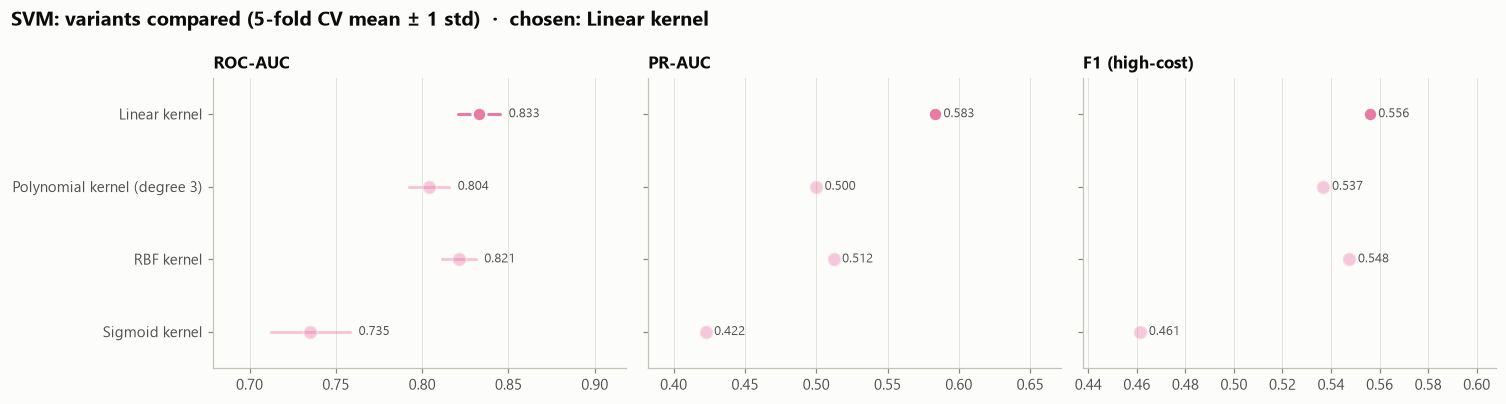

In [12]:
sub_idx, _ = train_test_split(np.arange(len(X)), train_size=5000, stratify=y, random_state=RANDOM_STATE)
Xs, ys, gs = (X.iloc[sub_idx].reset_index(drop=True), y.iloc[sub_idx].reset_index(drop=True),
              groups.iloc[sub_idx].reset_index(drop=True))
folds_s = cv_folds(Xs, ys, gs)
print(f"Subsample: {len(Xs):,} people, high-cost rate {ys.mean():.1%}")

table, res = run_variants("SVM", X_=Xs, y_=ys, folds_=folds_s, n_jobs=5)
ref = evaluate_cv(make_pipeline(preprocessor, *build("Logistic Regression", "L2 + balanced", pos_weight)),
                  Xs, ys, folds_s, n_jobs=5)
print("Reference - logistic regression on the same 5,000 people:")
display(summarize({"Logistic Regression (L2 + balanced)": ref}).astype(float).reindex(columns=list(COLS)).round(3).rename(columns=COLS))
fig = plot_variant_scores(table, "SVM", best=BEST["SVM"])
save_fig(fig, "05_variants_svm")
plt.show()

#### 📖 What this chart shows (in plain English)
(These results use the 5,000-person subsample.)

- **Linear 0.833**, RBF 0.821, polynomial 0.804, sigmoid 0.735.
- The **linear kernel wins**: curved boundaries don't help. The polynomial kernel overfits (training 0.916 vs validation 0.804), and the sigmoid kernel is poor, as it often is in practice.
- **Reference:** logistic regression on the *same* 5,000 people scores **0.834**, the same as the linear SVM. Both draw a straight boundary and differ only in their loss function (hinge vs log-loss).
- Scores here are higher than the full-data scores (0.833 vs 0.822) only because this is a different, smaller sample with its own folds; the standard deviation is three times larger (0.012). Compare numbers *within* this table only.

**Chosen: linear kernel.** Notebook 06 trains it on all 17,398 people.

## 6 · Naive Bayes

> **🎓 Theory in brief**
>
> Naive Bayes applies **Bayes' theorem**: P(high-cost | features) ∝ P(features | high-cost) × P(high-cost).
> 
> It is "naive" because it assumes every feature is **independent** of the others within each class, so it can simply multiply one probability per feature.
> - **Gaussian NB** assumes each feature follows a bell curve within each class.
> - **Bernoulli NB** treats each feature as yes/no.
> - The **prior** P(high-cost) is learned from the data (0.20) unless set by hand. Setting equal priors is Naive Bayes' version of class weighting.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#106-naive-bayes)*

**🛠️ What this code does:** Trains three Naive Bayes variants: Gaussian with learned priors, Gaussian with equal priors (50/50), and Bernoulli with equal priors. For Bernoulli, scaled numeric inputs are turned into "above average: yes/no".

  Gaussian NB, learned priors                   1.3 s


  Gaussian NB, equal priors                     1.3 s


  Bernoulli NB, equal priors                    1.5 s


,ROC-AUC,±,PR-AUC,F1,Recall,Precision,Train ROC-AUC,Fit time (s)
"Gaussian NB, learned priors",0.795,0.003,0.471,0.519,0.737,0.400,0.797,0.211
"Gaussian NB, equal priors",0.795,0.003,0.470,0.514,0.756,0.389,0.797,0.249
"Bernoulli NB, equal priors",0.800,0.003,0.531,0.503,0.763,0.376,0.800,0.374


Chosen variant (one-standard-error rule): Bernoulli NB, equal priors


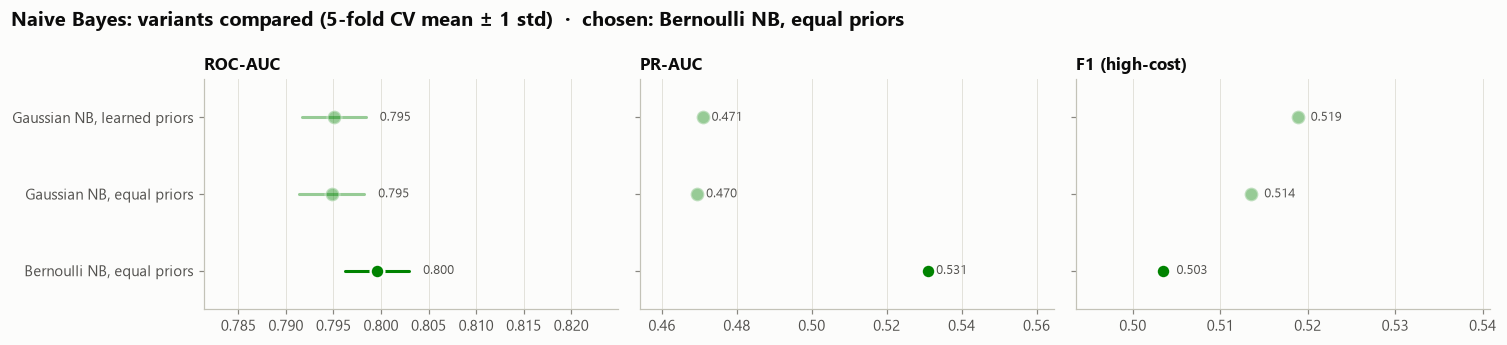

In [13]:
table, res = run_variants("Naive Bayes", n_jobs=5)
fig = plot_variant_scores(table, "Naive Bayes", best=BEST["Naive Bayes"])
save_fig(fig, "05_variants_naive_bayes")
plt.show()

#### 📖 What this chart shows (in plain English)
- ROC-AUC ≈ **0.795-0.800**, the weakest group apart from single trees. That is expected: the independence assumption is badly broken, since age, number of conditions and Medicare are strongly related.
- **Equal vs learned priors:** identical ROC-AUC, because the prior only shifts every score by the same amount. Recall rises slightly.
- **Bernoulli is best** (ROC-AUC 0.800, PR-AUC 0.531). Treating features as yes/no suits the many yes/no health flags.

**Chosen: Bernoulli NB with equal priors.** It is also very fast (0.25 s).

## 7 · Gradient Boosting

> **🎓 Theory in brief**
>
> Boosting builds trees **one after another**. Each new small tree (a **weak learner**) is trained to fix the errors the previous trees still make; technically, it fits the gradient of the loss. The final prediction adds up all the trees, each scaled down by the **learning rate**.
> - **More trees** let the model fit more detail, and eventually overfit.
> - A **lower learning rate** needs more trees but usually generalises better.
> - **`HistGradientBoosting`** first sorts each feature into at most 255 bins, which makes training much faster on large data. It also supports class weights.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#107-gradient-boosting)*

**🛠️ What this code does:** Trains three variants: classic `GradientBoostingClassifier` (200 trees of depth 3, no class weights, because it doesn't support them), and `HistGradientBoostingClassifier` (300 rounds, learning rate 0.05) with and without balanced class weights.

  sklearn GradientBoosting (unweighted)        20.4 s


  HistGradientBoosting (unweighted)             6.0 s


  HistGradientBoosting + balanced               5.9 s


,ROC-AUC,±,PR-AUC,F1,Recall,Precision,Train ROC-AUC,Fit time (s)
sklearn GradientBoosting (unweighted),0.824,0.004,0.560,0.458,0.357,0.640,0.858,19.155
HistGradientBoosting (unweighted),0.822,0.004,0.561,0.441,0.336,0.643,0.880,4.021
HistGradientBoosting + balanced,0.821,0.005,0.561,0.542,0.731,0.430,0.877,3.987


Chosen variant (one-standard-error rule): HistGradientBoosting + balanced


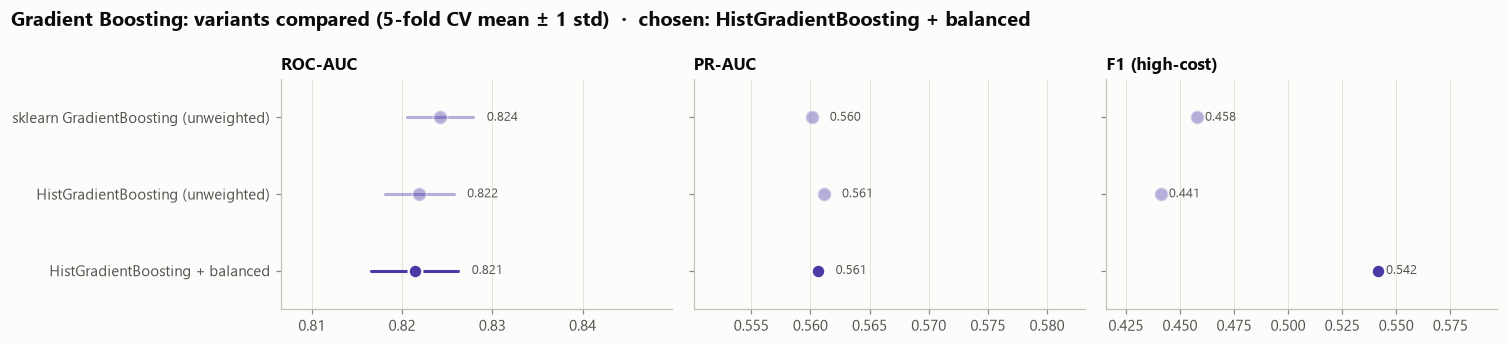

In [14]:
table, res = run_variants("Gradient Boosting", n_jobs=5)
fig = plot_variant_scores(table, "Gradient Boosting", best=BEST["Gradient Boosting"])
save_fig(fig, "05_variants_gradient_boosting")
plt.show()

#### 📖 What this chart shows (in plain English)
- All three score **0.821-0.824 ROC-AUC**, a tie within noise.
- The classic `GradientBoostingClassifier` takes **20.9 s** per fit against **≈ 4 s** for `HistGradientBoosting`. Histogram binning is 5 times faster with the same accuracy.
- Without class weights, recall is only 0.34-0.36. With balanced weights it is **0.73** (F1 0.542).

**Chosen: HistGradientBoosting + balanced.** It ties on ROC-AUC and has the best F1.

## 8 · XGBoost

> **🎓 Theory in brief**
>
> XGBoost ("eXtreme Gradient Boosting") is a fast, heavily optimised gradient-boosting library:
> - **Built-in regularisation:** L1 (`reg_alpha`) and L2 (`reg_lambda`) penalties on leaf values, plus a minimum gain needed to split.
> - **Second-order optimisation:** it uses both the gradient and the curvature of the loss.
> - **Row and column subsampling** (`subsample`, `colsample_bytree`) for extra randomness.
> - **`scale_pos_weight`** for imbalance; here it is set to the class ratio, ≈ 4.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#108-xgboost)*

**🛠️ What this code does:** Trains four XGBoost variants: no class weighting, `scale_pos_weight` ≈ 4, shallower trees (depth 3) with more rounds, and stronger L1/L2 regularisation.

  No class weighting                           10.5 s


  scale_pos_weight                             10.3 s


  scale_pos_weight, depth 3, 600 trees         13.6 s


  scale_pos_weight + stronger L1/L2            10.6 s


,ROC-AUC,±,PR-AUC,F1,Recall,Precision,Train ROC-AUC,Fit time (s)
No class weighting,0.825,0.003,0.564,0.457,0.358,0.633,0.887,1.543
scale_pos_weight,0.823,0.004,0.559,0.542,0.717,0.435,0.892,1.557
"scale_pos_weight, depth 3, 600 trees",0.824,0.003,0.565,0.546,0.733,0.435,0.874,2.176
scale_pos_weight + stronger L1/L2,0.824,0.003,0.564,0.544,0.728,0.435,0.885,1.560


Chosen variant (one-standard-error rule): scale_pos_weight, depth 3, 600 trees


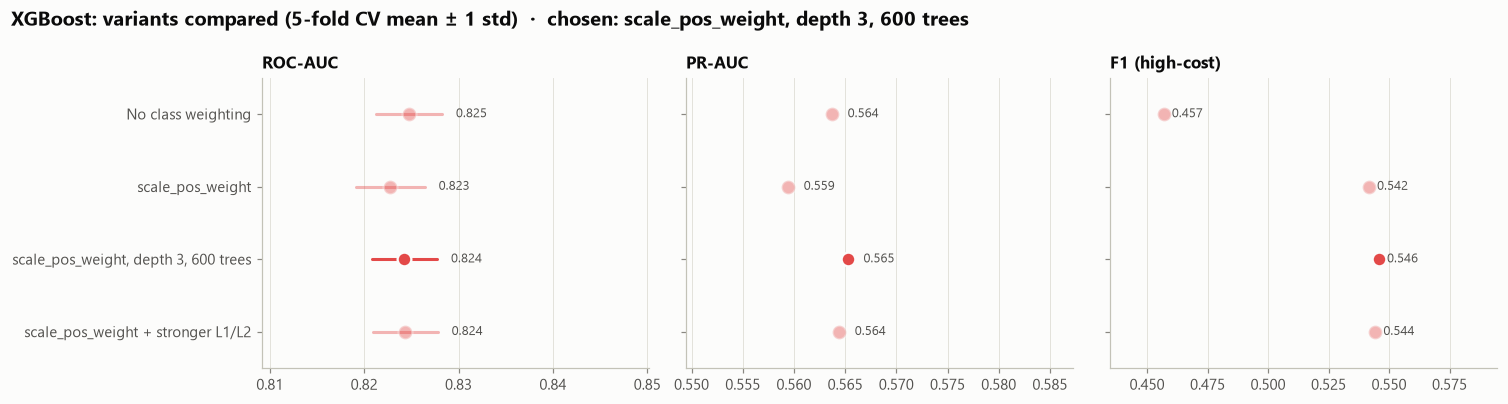

In [15]:
table, res = run_variants("XGBoost", n_jobs=None)   # XGBoost uses all CPU cores itself
fig = plot_variant_scores(table, "XGBoost", best=BEST["XGBoost"])
save_fig(fig, "05_variants_xgboost")
plt.show()

#### 📖 What this chart shows (in plain English)
- All four score **0.823-0.825** (std 0.003), a tie.
- **No weighting:** recall 0.36. **`scale_pos_weight`:** recall 0.72-0.73.
- **Shallower trees (depth 3) with more rounds** give the best F1 (0.546) and the smallest overfitting gap (training 0.874 vs 0.887-0.892 for the others).
- **Stronger L1/L2** changes nothing; there is little to regularise at these settings.

**Chosen: `scale_pos_weight`, depth 3, 600 trees.**

**🛠️ What this code does:** Shows **how boosting learns round by round**. On fold 1 only, it trains XGBoost for 1,500 rounds and records the ROC-AUC on the training part and on the validation part after every round.

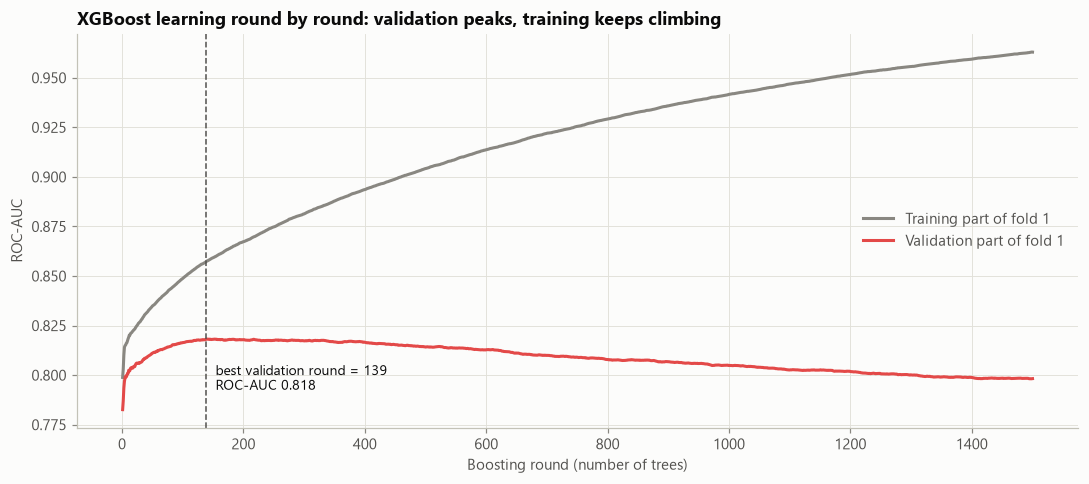

After 400 rounds (the default used here): validation ROC-AUC 0.8166; after 1,500: 0.7982; training after 1,500: 0.9629


In [16]:
tr_idx, va_idx = folds[0]
prep = clone(preprocessor).fit(X.iloc[tr_idx])
Xtr, Xva = prep.transform(X.iloc[tr_idx]), prep.transform(X.iloc[va_idx])
xgb_curve = XGBClassifier(n_estimators=1500, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                          scale_pos_weight=pos_weight, eval_metric="auc", n_jobs=-1, random_state=RANDOM_STATE)
xgb_curve.fit(Xtr, y.iloc[tr_idx], eval_set=[(Xtr, y.iloc[tr_idx]), (Xva, y.iloc[va_idx])], verbose=False)
ev = xgb_curve.evals_result()
train_auc, val_auc = np.array(ev["validation_0"]["auc"]), np.array(ev["validation_1"]["auc"])
best_round = int(np.argmax(val_auc)) + 1

fig, ax = plt.subplots(figsize=(10, 4.5))
rounds = np.arange(1, len(val_auc) + 1)
ax.plot(rounds, train_auc, color=INK_MUTED, label="Training part of fold 1")
ax.plot(rounds, val_auc, color=model_color("XGBoost"), label="Validation part of fold 1")
ax.axvline(best_round, color=INK_SECONDARY, linestyle="--", linewidth=1)
ax.text(best_round + 15, val_auc.min() + 0.01, f"best validation round = {best_round}\nROC-AUC {val_auc.max():.3f}", fontsize=9)
ax.set_xlabel("Boosting round (number of trees)")
ax.set_ylabel("ROC-AUC")
ax.legend(loc="center right")
ax.set_title("XGBoost learning round by round: validation peaks, training keeps climbing")
fig.tight_layout()
save_fig(fig, "05_xgboost_rounds_curve")
plt.show()
print(f"After 400 rounds (the default used here): validation ROC-AUC {val_auc[399]:.4f}; "
      f"after 1,500: {val_auc[-1]:.4f}; training after 1,500: {train_auc[-1]:.4f}")

#### 📖 What this chart shows (in plain English)
- The **training** ROC-AUC (grey) keeps rising with every tree, reaching **0.963** after 1,500 rounds. Boosting keeps fitting the training data more and more closely.
- The **validation** ROC-AUC (red) peaks early, at **round 139 (0.818)**, then slowly declines: 0.817 at round 400 and 0.798 at round 1,500. That decline is overfitting from too many trees.

**Lesson:** the number of trees must be tuned, or chosen with early stopping. A lower learning rate or shallower trees push the peak later. This is done in notebook 07.

## 9 · Voting ensemble

> **🎓 Theory in brief**
>
> An ensemble combines different models so that their mistakes partly cancel out.
> - **Hard voting:** each model casts one vote (high or low cost) and the majority wins.
> - **Soft voting:** the models' *probabilities* are averaged. It is usually better, because a very confident model counts more than an unsure one, and it produces a score for ROC-AUC.
> 
> The members here are logistic regression, a random forest and XGBoost: a linear model, a bagged model and a boosted model.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#109-ensembles-voting-and-stacking)*

**🛠️ What this code does:** Trains hard and soft voting with the same three members. Hard voting gives only yes/no answers, so it has no ROC-AUC or PR-AUC; those cells show *n/a*.

  Hard voting (LR + RF + XGB)                  23.1 s


  Soft voting (LR + RF + XGB)                  24.5 s


,ROC-AUC,±,PR-AUC,F1,Recall,Precision,Train ROC-AUC,Fit time (s)
Hard voting (LR + RF + XGB),NaN,NaN,NaN,0.548,0.704,0.449,NaN,3.467
Soft voting (LR + RF + XGB),0.826,0.004,0.568,0.552,0.703,0.455,0.892,3.469


Chosen variant (one-standard-error rule): Soft voting (LR + RF + XGB)


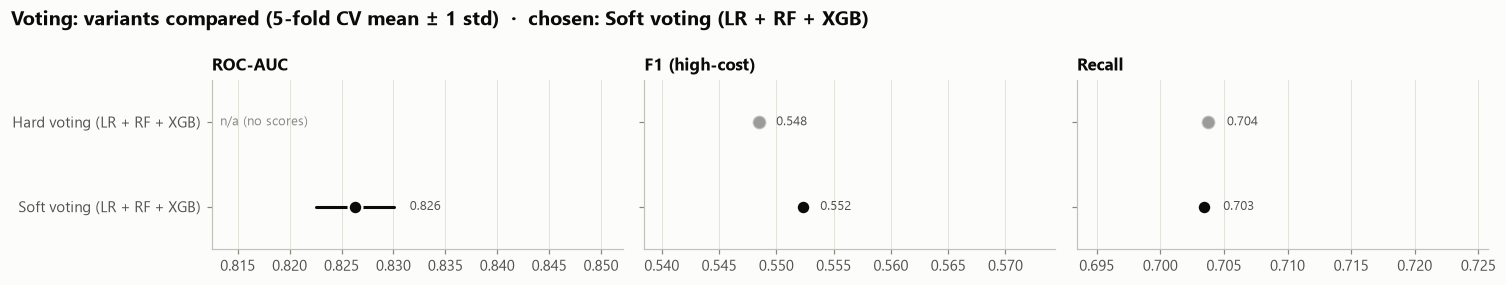

In [17]:
table, res = run_variants("Voting", n_jobs=None)
fig = plot_variant_scores(table, "Voting", metrics=("roc_auc", "f1", "recall"), best=BEST["Voting"])
save_fig(fig, "05_variants_voting")
plt.show()

#### 📖 What this chart shows (in plain English)
- **Soft voting:** ROC-AUC **0.826**, PR-AUC 0.568, F1 0.552. That is slightly better than each member alone (logistic regression 0.822, random forest 0.821, XGBoost ≈ 0.823).
- **Hard voting:** similar F1 (0.548), but it produces no scores, so it has no ROC/PR curve and its threshold can't be moved.
- The gain is small because the members largely **agree**: they learned the same signals from the same features.

**Chosen: soft voting.**

## 10 · Seeing how each algorithm draws its boundary

**🛠️ What this code does:** Trains each algorithm on just **two features**, age (`AGELAST`) and number of chronic conditions (`N_CONDITIONS`), using 4,000 people, so the decision can be drawn on a flat map.
- **Background colour:** the predicted probability of being high-cost (blue = low, red = high).
- **Black line:** the 50% boundary.
- **Dots:** a sample of real people, jittered slightly so they don't overlap.

This is only an illustration: with two features the models are much weaker than with all 37.

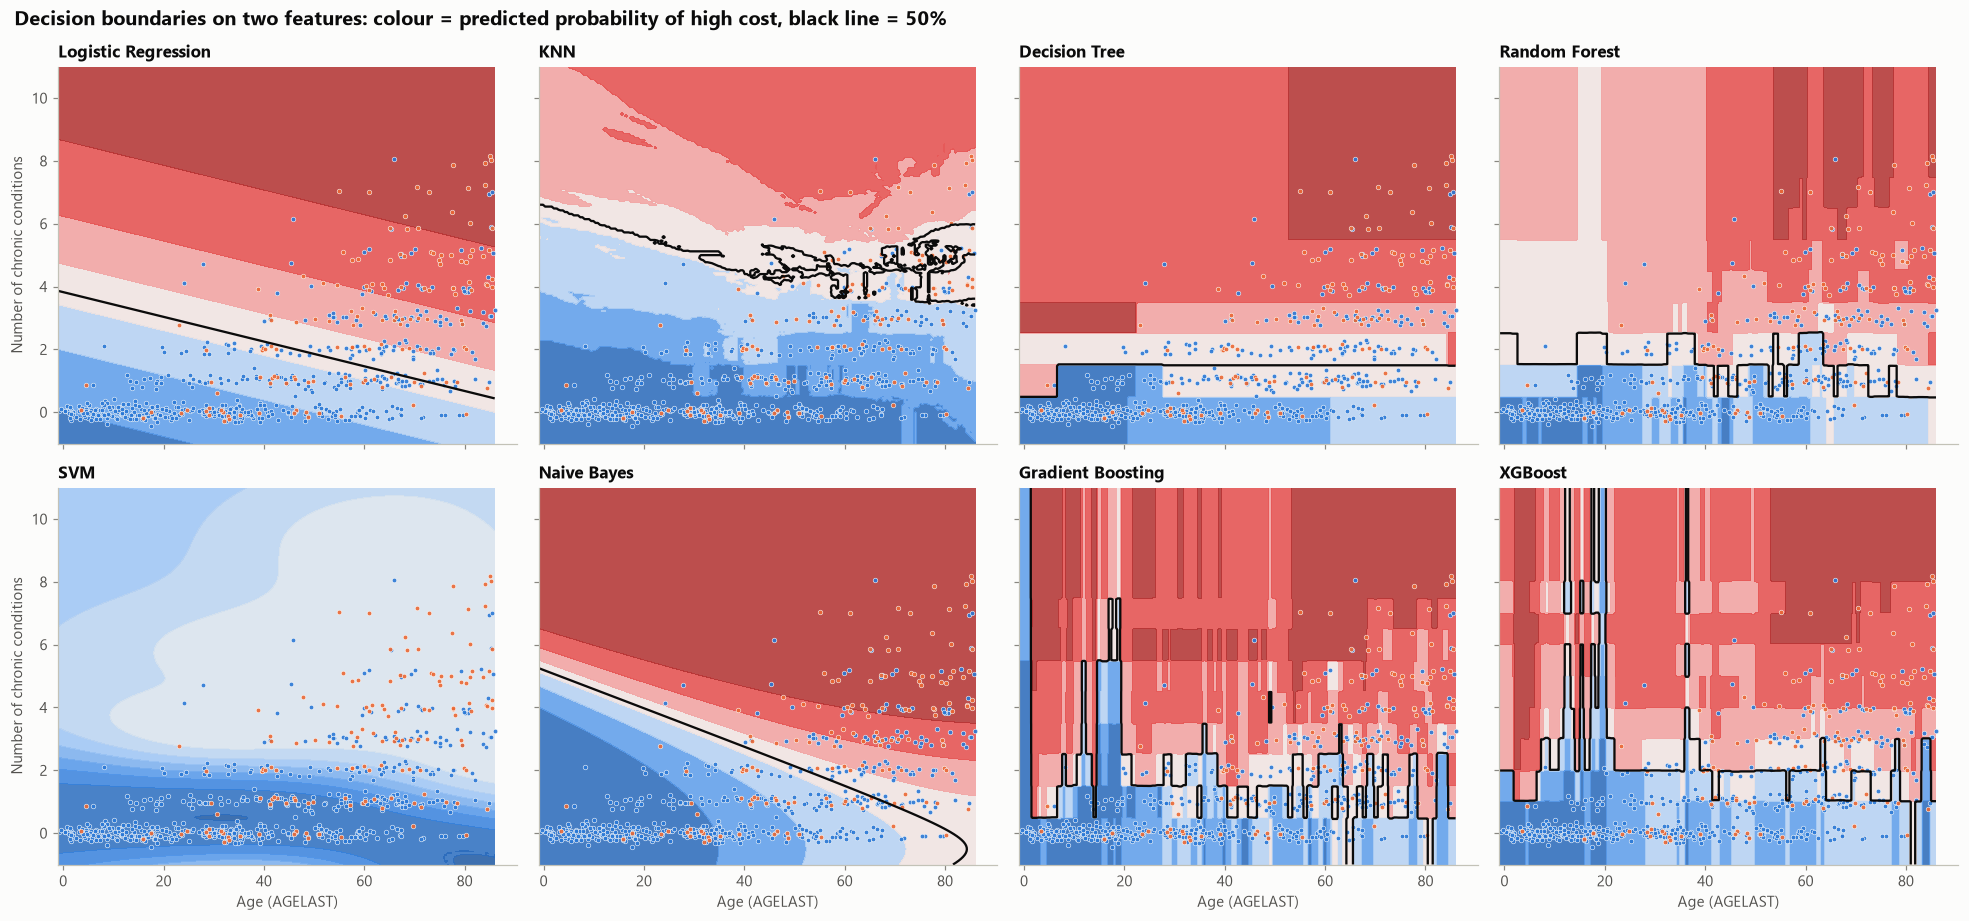

In [18]:
two = ["AGELAST", "N_CONDITIONS"]
idx2, _ = train_test_split(np.arange(len(X)), train_size=4000, stratify=y, random_state=RANDOM_STATE)
X2, y2 = X.iloc[idx2][two].to_numpy(dtype=float), y.iloc[idx2].to_numpy()
demo = {
    "Logistic Regression": LogisticRegression(class_weight="balanced"),
    "KNN": KNeighborsClassifier(n_neighbors=75),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=20, class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "SVM": SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=RANDOM_STATE),
    "Naive Bayes": GaussianNB(priors=[0.5, 0.5]),
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, scale_pos_weight=pos_weight,
                             n_jobs=-1, random_state=RANDOM_STATE),
}
rng = np.random.default_rng(0)
show_idx = rng.choice(len(X2), 700, replace=False)
jitter = X2[show_idx] + rng.normal(0, [0.6, 0.15], size=(len(show_idx), 2))

fig, axes = plt.subplots(2, 4, figsize=(18, 8.5), sharex=True, sharey=True)
for ax, (name, model) in zip(axes.ravel(), demo.items()):
    pipe = Pipeline([("scale", StandardScaler()), ("model", model)]).fit(X2, y2)
    DecisionBoundaryDisplay.from_estimator(pipe, X2, response_method="predict_proba", cmap=DIVERGING, vmin=0, vmax=1,
                                           alpha=0.85, grid_resolution=200, ax=ax, xlabel="", ylabel="")
    DecisionBoundaryDisplay.from_estimator(pipe, X2, response_method="predict_proba", plot_method="contour",
                                           levels=[0.5], colors=INK, linewidths=1.5, grid_resolution=200, ax=ax,
                                           xlabel="", ylabel="")
    for cls, color in [(0, LOW_COST_COLOR), (1, HIGH_COST_COLOR)]:
        m = y2[show_idx] == cls
        ax.scatter(jitter[m, 0], jitter[m, 1], s=9, color=color, edgecolor=SURFACE, linewidth=0.4, alpha=0.9)
    ax.set_title(name, fontsize=11)
    ax.grid(False)
for ax in axes[1]:
    ax.set_xlabel("Age (AGELAST)")
for ax in axes[:, 0]:
    ax.set_ylabel("Number of chronic conditions")
fig.suptitle("Decision boundaries on two features: colour = predicted probability of high cost, black line = 50%",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "05_decision_boundaries")
plt.show()

#### 📖 What this chart shows (in plain English)
Each panel shows how one algorithm divides the "age × number of conditions" map:

- **Logistic regression:** a straight diagonal line. Risk rises steadily with both features.
- **Naive Bayes:** a smooth curve (Gaussian Naive Bayes boundaries are quadratic).
- **Decision tree:** rectangular steps, because it asks one axis-aligned question at a time.
- **Random forest, Gradient Boosting, XGBoost:** many small steps, as averages or sums of trees. The boosting models carve thin vertical strips at particular ages. They are chasing noise, which is easy to see in this small two-feature demo.
- **KNN:** an irregular, blob-like boundary that follows local groups of people.
- **SVM:** mostly blue and with no 50% line. With `probability=True`, scikit-learn calibrates the SVM's scores using internal cross-validation (Platt scaling), and that undoes the class weighting. Because the real high-cost rate is below 50% almost everywhere on this map, no region reaches 50%. The shading still shows the same pattern: risk rises with the number of conditions.

All eight agree on the **big picture**: more conditions and older age mean higher risk. They differ only in the details, and on the full data those details produce almost the same scores.

## 11 · Best variant of each algorithm

**🛠️ What this code does:** Collects every variant's result into one table (saved as `reports/results/variant_results.csv`), lists the variant chosen for each algorithm by the one-standard-error rule, saves the choices to `reports/results/best_variants.json` for notebook 06, and charts the winners.

,best variant,ROC-AUC,±,PR-AUC,F1,Train ROC-AUC,Fit time (s)
algorithm,,,,,,,
SVM,Linear kernel,0.833,0.012,0.583,0.556,0.849,2.812
Voting,Soft voting (LR + RF + XGB),0.826,0.004,0.568,0.552,0.892,3.469
XGBoost,"scale_pos_weight, depth 3, 600 trees",0.824,0.003,0.565,0.546,0.874,2.176
Logistic Regression,L2 + balanced,0.822,0.004,0.566,0.543,0.828,0.601
Gradient Boosting,HistGradientBoosting + balanced,0.821,0.005,0.561,0.542,0.877,3.987
Random Forest,"300 trees, min_samples_leaf=5",0.821,0.004,0.553,0.550,0.933,1.885
KNN,"k=75, uniform, euclidean",0.811,0.004,0.539,0.359,0.828,0.223
Naive Bayes,"Bernoulli NB, equal priors",0.800,0.003,0.531,0.503,0.800,0.374
Decision Tree,"Entropy, max_depth=6",0.792,0.005,0.487,0.509,0.820,0.328


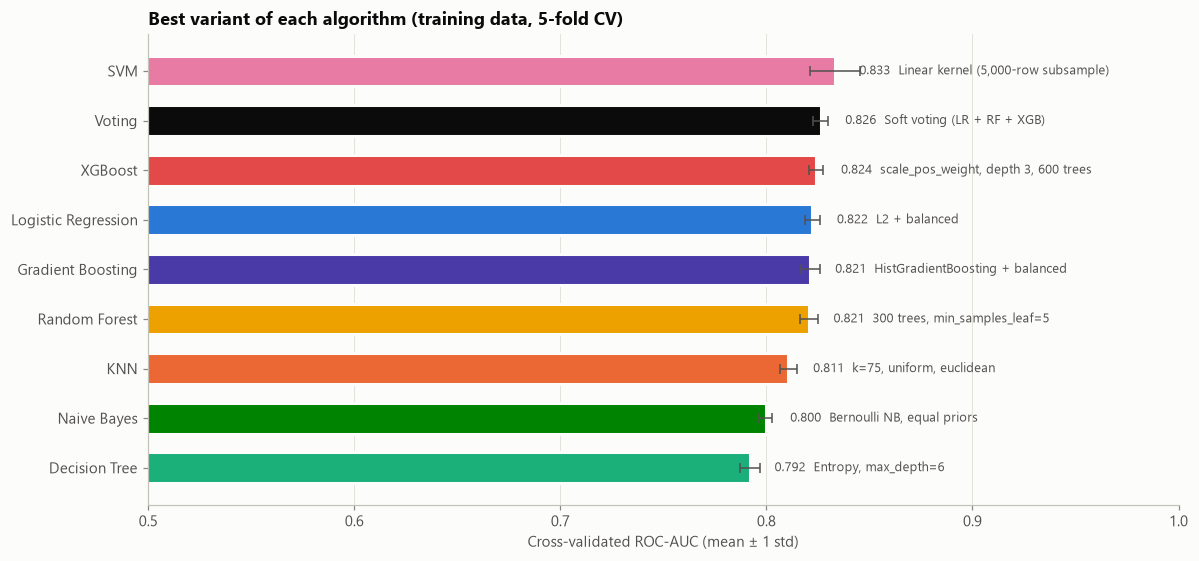

In [19]:
all_rows = pd.concat({algo: t for algo, t in ALL.items()}, names=["algorithm", "variant"])
all_rows.round(4).to_csv(RESULTS / "variant_results.csv")

best = dict(BEST)
save_best_variants(best)
summary = pd.DataFrame([{"algorithm": a, "best variant": v, **ALL[a].loc[v, ["roc_auc", "roc_auc_std", "pr_auc", "f1",
                                                                           "train_roc_auc", "fit_time_s"]].to_dict()}
                        for a, v in best.items()]).set_index("algorithm").sort_values("roc_auc", ascending=False)
display(summary.round(3).rename(columns=COLS))

fig, ax = plt.subplots(figsize=(11, 5.2))
order = summary.index.tolist()
ax.barh(order, summary["roc_auc"], xerr=summary["roc_auc_std"], color=[model_color(a) for a in order],
        height=0.62, edgecolor=SURFACE, linewidth=2, error_kw={"ecolor": INK_SECONDARY, "capsize": 3, "lw": 1})
for i, (a, r) in enumerate(summary.iterrows()):
    note = " (5,000-row subsample)" if a == "SVM" else ""
    ax.text(r["roc_auc"] + 0.012, i, f"{r['roc_auc']:.3f}  {r['best variant']}{note}", va="center", fontsize=8.5,
            color=INK_SECONDARY)
ax.invert_yaxis()
ax.set_xlim(0.5, 1.0)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Cross-validated ROC-AUC (mean ± 1 std)")
ax.set_title("Best variant of each algorithm (training data, 5-fold CV)")
fig.tight_layout()
save_fig(fig, "05_best_variants")
plt.show()

#### 📖 What this chart shows (in plain English)
Ranking of the chosen variants by 5-fold CV ROC-AUC:

- **Top group (0.821-0.826):** soft voting, XGBoost, logistic regression, HistGradientBoosting and random forest. They sit within about 0.005 of each other, which is only one or two fold standard deviations.
- **SVM (0.833)** was scored on the 5,000-person subsample, so its number is *not comparable* with the others. Its fair, full-data score comes in notebook 06.
- **Lower group:** KNN 0.811, Bernoulli Naive Bayes 0.800, decision tree 0.792.

**The big lesson:** simple **logistic regression is as good as the complex models** on this data. The relationship is mostly *additive and one-directional*: more conditions, older age and worse health all mean higher cost, so flexible models find little extra signal. Notebook 06 puts the winners through identical, full-data tests and checks whether the small differences are statistically real.

## Summary

| Algorithm | Chosen variant | CV ROC-AUC | F1 |
|---|---|---|---|
| Voting | Soft voting (LR + RF + XGB) | 0.826 | 0.552 |
| XGBoost | `scale_pos_weight`, depth 3, 600 trees | 0.824 | 0.546 |
| Logistic Regression | L2 + balanced | 0.822 | 0.543 |
| Gradient Boosting | HistGradientBoosting + balanced | 0.821 | 0.542 |
| Random Forest | 300 trees, `min_samples_leaf=5` | 0.821 | 0.550 |
| KNN | k = 75, uniform, Euclidean | 0.811 | 0.359 |
| Naive Bayes | Bernoulli, equal priors | 0.800 | 0.503 |
| Decision Tree | Entropy, `max_depth=6` | 0.792 | 0.509 |
| SVM | Linear kernel | 0.833 *(5,000-row subsample)* | 0.556 |

**What we learned:**
1. **Imbalance handling** (class weights, `scale_pos_weight`, equal priors, SMOTE) changes recall, precision and F1 at the 0.5 threshold, but hardly changes ranking skill (ROC-AUC).
2. **Overfitting is easy to see:** an unlimited tree scores 1.000 on training data and 0.611 on validation; KNN with k = 5 scores 0.904 vs 0.736; XGBoost's validation score peaks after about 140 rounds and then falls.
3. **Scaling matters** for distance-based models: KNN drops from 0.811 to 0.727 without it.
4. **Straight boundaries are enough here.** Logistic regression ties with boosting and forests, and the best SVM kernel is the linear one.
5. **Ensembles add little** when their members agree (soft voting +0.004).

All variant scores are saved in `reports/results/variant_results.csv` and the chosen variants in `best_variants.json`.

**Next:** `06_model_comparison.ipynb` compares the 9 chosen models head to head on identical terms.